# 实验四：用 NumPy 实现神经网络与反向传播 · 参考答案

主线：前向传播 → 损失 → 反向传播 → 独立梯度检查 → 单次更新 → 完整训练 → 受控对照。

**必做 Q1–Q8；Q9 为进阶任务；Q10 为可跳过的教师演示。** 不要求预先安装 PyTorch。

在本实验目录启动 notebook，使用安装了 NumPy、Matplotlib 的 Python 3 环境。Q2–Q6 先写独立函数，Q7 再整理进网络类。
学生版 TODO 会抛出 `NotImplementedError`；这是待完成位置，不是环境故障。按顺序填写后重启 kernel 全量运行。

> 相关说明：
>
> 1. Pytorch 是专业的模型训练工具包，里面函数实现了大部分内容。尤其是如果打开 `autograd`，后面的 BP 基本就可以不用看了。这里用 Numpy 手动实现一次，是希望大家能在复现的过程中逐步将我们的理论与代码联系起来。后续就不会用这么笨的方法了。
> 2. 有关 Pytorch 的安装是一件比较麻烦的事情，整个包很大，也涉及到电脑 CPU/GPU 型号及版本等各种问题，具体详见补发的 Pytorch 安装辅助文件。如果实在觉得麻烦跳过 Q10 即可，**Q10不算分**。
> 3. 开始完成实验的之前，**强烈建议自己在草稿纸上完整推一遍算法流程**，因为后面的代码会非常抽象，有张图用于参考会方便很多。

## 实验约定

本实验用无噪声样本拟合正弦函数，样本按行排列。这里的 `linspace(a, b, n)` 指的是在区间 $[a,b]$ 上均匀抽取 $n$ 个点：

$$
X=\operatorname{linspace}(-\pi,\pi,64),\qquad y=\sin(X).
$$

代码将二者整理为 `(64, 1)`，统一使用 `float64`。网络只有一个隐藏层：

$$
Z_1=XW_1+b_1,\qquad A_1=\tanh(Z_1),\qquad \hat y=A_1W_2+b_2.
$$

输出层采用线性输出。损失为

$$
L=\frac1N\sum_{i=1}^N(\hat y_i-y_i)^2,
$$

即 `mean((y_pred - y) ** 2)`，**不含额外的 $1/2$**。


Python: /opt/homebrew/Caskroom/miniforge/base/envs/ai-lab/bin/python
NumPy: 2.5.3 Matplotlib: 3.11.2
{'N': 64, 'H': 16, 'seed': 42, 'lr': 0.02, 'epochs': 10000, 'dtype': 'float64'}


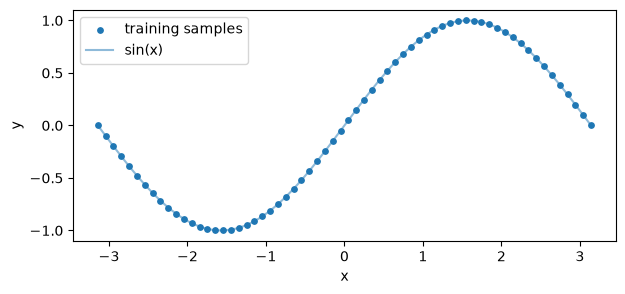

In [1]:
from pathlib import Path
import sys
import matplotlib
import numpy as np
import matplotlib.pyplot as plt

from lab_utils import make_sine_data, gradient_check, plot_results

print("Python:", sys.executable)
print("NumPy:", np.__version__, "Matplotlib:", matplotlib.__version__)

HIDDEN_DIM, SEED = 16, 42
LR, EPOCHS = 0.02, 10000
X, y = make_sine_data(n_samples=64, noise_std=0.0, seed=SEED)
grid = np.linspace(-np.pi, np.pi, 400, dtype=np.float64).reshape(-1, 1)
print(
    {
        "N": len(X),
        "H": HIDDEN_DIM,
        "seed": SEED,
        "lr": LR,
        "epochs": EPOCHS,
        "dtype": str(X.dtype),
    }
)
plt.figure(figsize=(7, 3))
plt.scatter(X[:, 0], y[:, 0], s=15, label="training samples")
plt.plot(grid[:, 0], np.sin(grid[:, 0]), label="sin(x)", alpha=0.5)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


## Q1 · 形状与计算图（必做）

样本按行存放，输出层保持线性。补全下表，画出依赖关系，并解释偏置如何作用于所有样本。

$$Z_1=XW_1+b_1,\quad A_1=\tanh(Z_1),\quad \hat y=A_1W_2+b_2.$$

| 量         | 一般形状       | 本次具体形状     |
| ---------- | -------------- | ---------------- |
| X、y、预测 | (N, 1)         | (64, 1)          |
| W1、b1     | (1, H)、(1, H) | (1, 16)、(1, 16) |
| Z1、A1     | (N, H)         | (64, 16)         |
| W2、b2     | (H, 1)、(1, 1) | (16, 1)、(1, 1)  |

写出 `X @ W1` 和 `A1 @ W2` 乘法中消去的维度。为什么不能把 y 随意改为 `(N,)`？


**参考解释：** X、y、预测均为 (64,1)；W1、b1 为 (1,16)；Z1、A1 为 (64,16)；W2 为 (16,1)，b2 为 (1,1)。

计算图为 X、W1、b1 → Z1 → A1，与 W2、b2 → 预测，与 y → L。第一步消去输入维度 1，第二步消去隐藏维度 H。
偏置沿样本轴广播，每一行共享同一参数。若 y 为 (N,)，与 (N,1) 预测相减可能广播成 (N,N)，程序仍运行却计算了错误的误差。


In [2]:
def initial_params(hidden_dim=16, seed=42):
    """教师提供：与后续 TwoLayerNet 完全相同的初始化顺序。"""
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0.0, 1.0, size=(1, hidden_dim))
    W2 = rng.normal(0.0, 1.0 / np.sqrt(hidden_dim), size=(hidden_dim, 1))
    return {"W1": W1, "b1": np.zeros((1, hidden_dim)), "W2": W2, "b2": np.zeros((1, 1))}


params = initial_params(HIDDEN_DIM, SEED)
for name, value in params.items():
    print(name, value.shape)
assert X.shape == y.shape == (64, 1)


W1 (1, 16)
b1 (1, 16)
W2 (16, 1)
b2 (1, 1)


## Q2 · 前向传播（必做）

实现 `forward_pass(X, params, activation='tanh')`，返回 `(y_pred, cache)`。
cache 至少保存 X、Z1、A1，供反向传播复用。为 Q8 预留 `linear` 分支：A1=Z1。
本题不改变参数，也不在输出层使用 tanh。完成后运行形状检查，并解释缓存为什么不能用训练后的一组参数重新计算。


In [3]:
def forward_pass(X, params, activation="tanh"):
    Z1 = X @ params["W1"] + params["b1"]
    if activation == "tanh":
        A1 = np.tanh(Z1)
    elif activation == "linear":
        A1 = Z1
    else:
        raise ValueError("activation 必须是 tanh 或 linear")
    y_pred = A1 @ params["W2"] + params["b2"]
    return y_pred, {"X": X, "Z1": Z1, "A1": A1}


In [4]:
before = {k: v.copy() for k, v in params.items()}
y_pred, cache = forward_pass(X, params)
assert y_pred.shape == (len(X), 1)
assert cache["Z1"].shape == cache["A1"].shape == (len(X), HIDDEN_DIM)
assert all(np.array_equal(params[k], before[k]) for k in params)
print("forward shapes passed; first predictions:", y_pred[:3, 0])


forward shapes passed; first predictions: [-1.89874526 -1.88618278 -1.87278526]


**参考解释：** 缓存属于本次前向计算的参数状态；反向传播必须对同一个计算图求导。先更新再用旧缓存反传，会混合不同参数状态。


## Q3 · 均方误差（必做）

实现标量损失 `loss_mse(y_pred, y)`，要求输入形状一致且为 (N,1)，不允许靠广播猜测。

$$L=\frac1N\sum_{i=1}^N(\hat y_i-y_i)^2,\qquad \frac{\partial L}{\partial \hat y}=\frac{2}{N}(\hat y-y).$$

本实验不含 1/2。回答：为什么求导时有 2？已经在 dY 中除以 N 后，后续权重梯度还需要再平均吗？


In [5]:
def loss_mse(y_pred, y):
    if y_pred.shape != y.shape or y.ndim != 2 or y.shape[1] != 1:
        raise ValueError("预测与标签必须同为 (N,1)")
    if len(y) == 0:
        raise ValueError("样本不能为空")
    return float(np.mean((y_pred - y) ** 2))


In [6]:
assert loss_mse(np.array([[1.0], [3.0]]), np.array([[0.0], [1.0]])) == 2.5
assert loss_mse(y, y) == 0.0
try:
    loss_mse(y, y[:, 0])
except ValueError:
    print("拒绝了可能意外广播的标签形状")
else:
    raise AssertionError("应拒绝 (N,) 标签")
print("initial MSE =", loss_mse(y_pred, y))


拒绝了可能意外广播的标签形状
initial MSE = 0.8042417068752801


**参考解释：** 平方项求导产生 2，样本平均产生 1/N。dY 已含平均系数，后续链式法则只需要矩阵乘法与偏置求和；重复除以 N 会使梯度错误缩小。


## Q4 · 反向传播（必做）

从输出误差向输入方向逐层求导，完成 `backward_pass`，返回 W1、b1、W2、b2 的梯度字典。
先在纸上写出 dY、dW2、db2、dA1、dZ1、dW1、db1 的公式与形状，再实现。
tanh 的导数可由缓存 A1 表示，linear 的导数为 1。

**检查点：** 梯度形状与参数完全相同；偏置沿哪个轴求和？为什么需要 `keepdims=True`？本函数不得修改任何参数。


In [7]:
def backward_pass(y_pred, y, cache, params, activation="tanh"):
    dY = 2.0 * (y_pred - y) / len(y)
    dW2 = cache["A1"].T @ dY
    db2 = np.sum(dY, axis=0, keepdims=True)
    dA1 = dY @ params["W2"].T
    if activation == "tanh":
        dZ1 = dA1 * (1.0 - cache["A1"] ** 2)
    elif activation == "linear":
        dZ1 = dA1
    else:
        raise ValueError("activation 必须是 tanh 或 linear")
    dW1 = cache["X"].T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}


In [8]:
before = {k: v.copy() for k, v in params.items()}
grads = backward_pass(y_pred, y, cache, params)
assert set(grads) == set(params)
for name in params:
    assert grads[name].shape == params[name].shape
    assert np.all(np.isfinite(grads[name]))
    assert np.array_equal(params[name], before[name])
    print(name, grads[name].shape, "gradient norm:", np.linalg.norm(grads[name]))


W1 (1, 16) gradient norm: 1.1961136674289317
b1 (1, 16) gradient norm: 8.929854356497347e-17
W2 (16, 1) gradient norm: 4.5373365875842575
b2 (1, 1) gradient norm: 1.942890293094024e-16


**参考推导：** dY 为 (N,1)；dW2=A1ᵀdY 为 (H,1)；db2=sum(dY,axis=0) 为 (1,1)。
dA1=dY W2ᵀ 为 (N,H)；dZ1=dA1⊙(1−A1²) 为 (N,H)；dW1=XᵀdZ1 为 (1,H)；db1=sum(dZ1,axis=0) 为 (1,H)。
同一个偏置被所有样本使用，因此累加每个样本对它的贡献；保留轴使梯度与参数具有相同二维形状。


## Q5 · 用有限差分独立检查梯度（必做）

教师提供 `gradient_check`，逐元素比较手写梯度与中心差分：

$$g_j^{num}=\frac{L(\theta+\epsilon e_j)-L(\theta-\epsilon e_j)}{2\epsilon}.$$

使用 H=3、seed=7 和三个样本，同时检查 tanh 与 linear。下方适配器仅将分步函数接到工具接口，尚未要求整理为正式网络类。
记录每组参数最大绝对误差、最大相对误差和 passed。判据使用绝对与相对误差结合，不能只看接近零梯度的相对误差。

解释：为什么损失下降不能替代梯度检查？epsilon 是否越小越好？若失败，按形状 → 平均系数 → 偏置求和 → 激活导数 → 转置次序排查。


In [9]:
class FunctionAdapter:
    def __init__(self, params, activation="tanh"):
        self.params = params
        self.activation = activation

    def forward(self, X):
        return forward_pass(X, self.params, self.activation)

    def backward(self, y_pred, y, cache):
        return backward_pass(y_pred, y, cache, self.params, self.activation)


X_small = np.array([[-0.7], [0.2], [0.9]], dtype=np.float64)
y_small = np.sin(X_small)
for activation in ("tanh", "linear"):
    adapter = FunctionAdapter(initial_params(3, 7), activation)
    saved = {k: v.copy() for k, v in adapter.params.items()}
    report = gradient_check(
        adapter, X_small, y_small, epsilon=1e-5, atol=1e-7, rtol=1e-4
    )
    print(activation, report)
    assert all(item["passed"] for item in report.values())
    assert all(np.array_equal(saved[k], adapter.params[k]) for k in saved)
print("两种激活的梯度通过检查，扰动后参数已恢复")


tanh {'W1': {'max_abs_error': 8.354650304909228e-12, 'max_rel_error': 1.1152349456417328e-11, 'passed': True}, 'b1': {'max_abs_error': 2.8543695185234697e-12, 'max_rel_error': 2.6302591571452232e-11, 'passed': True}, 'W2': {'max_abs_error': 5.573014272286514e-12, 'max_rel_error': 2.8419153188043576e-10, 'passed': True}, 'b2': {'max_abs_error': 9.633960296184796e-14, 'max_rel_error': 2.35177203233587e-13, 'passed': True}}
linear {'W1': {'max_abs_error': 2.2851998071615753e-12, 'max_rel_error': 5.982812961645613e-12, 'passed': True}, 'b1': {'max_abs_error': 5.420643101050615e-12, 'max_rel_error': 5.0509780530009164e-11, 'passed': True}, 'W2': {'max_abs_error': 4.434166900844916e-12, 'max_rel_error': 2.4772534834538874e-09, 'passed': True}, 'b2': {'max_abs_error': 2.128380804933272e-12, 'max_rel_error': 5.206075033834764e-12, 'passed': True}}
两种激活的梯度通过检查，扰动后参数已恢复


**参考解释：** 下降方向不唯一，梯度漏乘系数甚至部分分量错误时仍可能下降；有限差分为每个参数提供独立数值依据。
epsilon 太大有截断误差，太小会因两个接近损失相减而放大浮点舍入误差。通过只是这组样本附近的证据，不能证明全部输入都正确。
本单元输出的实际误差应作为记录；不要把示例阈值当成需要抄写的测量值。


## Q6 · 单次参数更新（必做）

实现 `update_params(params, grads, lr)`，按 θ←θ−lr·g 原地更新参数并返回 None；不能修改 grads。
使用小网络和小步长，比较更新前后损失。说明反向传播与梯度下降各做什么，并解释为什么任意学习率都下降是不成立的。


In [10]:
def update_params(params, grads, lr):
    for name in params:
        params[name] -= lr * grads[name]


In [11]:
one_step_params = initial_params(3, 7)
pred_before, cache_before = forward_pass(X_small, one_step_params)
loss_before = loss_mse(pred_before, y_small)
one_step_grads = backward_pass(pred_before, y_small, cache_before, one_step_params)
grad_copy = {k: v.copy() for k, v in one_step_grads.items()}
param_copy = {k: v.copy() for k, v in one_step_params.items()}
small_lr = 1e-3
assert update_params(one_step_params, one_step_grads, small_lr) is None
for name in one_step_params:
    np.testing.assert_allclose(
        one_step_params[name], param_copy[name] - small_lr * grad_copy[name]
    )
    np.testing.assert_array_equal(one_step_grads[name], grad_copy[name])
loss_after = loss_mse(forward_pass(X_small, one_step_params)[0], y_small)
print({"before": loss_before, "after": loss_after, "lr": small_lr})
assert loss_after < loss_before


{'before': 0.29740597472661073, 'after': 0.29692424258044253, 'lr': 0.001}


**参考解释：** BP 只计算当前损失对参数的导数，参数不变；梯度下降选择步长并修改参数。负梯度是局部下降方向，大步可能越过低损失区域，因此本题的小步下降检查不能推广到任意学习率。


## Q7 · 整理为网络类并完成训练（必做）

把已验证的计算整理到 `nn_numpy.py` 中：完成 `mse_loss`、`TwoLayerNet.forward/backward/step`。
类只负责初始化、前向、反向和更新，训练循环保留在本 notebook。保持缓存键与参数键一致，支持两种激活。
修改模块后重新运行导入单元；最终务必重启 kernel 全量执行。

下方先比较分步函数与封装结果，再检查封装后的梯度。训练骨架的每步顺序为：当前参数前向 → 损失 → 反向 → 更新 → 重新前向计算记录损失。
`history[k]` 表示完成 k 次更新后的 MSE，包含第 0 次初始损失；不能把更新前损失错当最终损失。

教师已提供数值异常处理：发现非有限损失、梯度或参数时停止，并恢复到最近一次有限状态。截断曲线必须结合 status 解读。


In [12]:
import importlib
import nn_numpy_参考答案 as nn_module

importlib.reload(nn_module)
TwoLayerNet, mse_loss = nn_module.TwoLayerNet, nn_module.mse_loss

for activation in ("tanh", "linear"):
    model = TwoLayerNet(hidden_dim=3, seed=7, activation=activation)
    separate = initial_params(3, 7)
    for name in separate:
        np.testing.assert_array_equal(model.params[name], separate[name])
    p_class, c_class = model.forward(X_small)
    p_func, c_func = forward_pass(X_small, separate, activation)
    np.testing.assert_allclose(p_class, p_func)
    assert np.isclose(mse_loss(p_class, y_small), loss_mse(p_func, y_small))
    g_class = model.backward(p_class, y_small, c_class)
    g_func = backward_pass(p_func, y_small, c_func, separate, activation)
    for name in g_func:
        np.testing.assert_allclose(g_class[name], g_func[name])
    report = gradient_check(model, X_small, y_small)
    print("class", activation, report)
    assert all(v["passed"] for v in report.values())


class tanh {'W1': {'max_abs_error': 8.354650304909228e-12, 'max_rel_error': 1.1152349456417328e-11, 'passed': True}, 'b1': {'max_abs_error': 2.8543695185234697e-12, 'max_rel_error': 2.6302591571452232e-11, 'passed': True}, 'W2': {'max_abs_error': 5.573014272286514e-12, 'max_rel_error': 2.8419153188043576e-10, 'passed': True}, 'b2': {'max_abs_error': 9.633960296184796e-14, 'max_rel_error': 2.35177203233587e-13, 'passed': True}}
class linear {'W1': {'max_abs_error': 2.2851998071615753e-12, 'max_rel_error': 5.982812961645613e-12, 'passed': True}, 'b1': {'max_abs_error': 5.420643101050615e-12, 'max_rel_error': 5.0509780530009164e-11, 'passed': True}, 'W2': {'max_abs_error': 4.434166900844916e-12, 'max_rel_error': 2.4772534834538874e-09, 'passed': True}, 'b2': {'max_abs_error': 2.128380804933272e-12, 'max_rel_error': 5.206075033834764e-12, 'passed': True}}


In [13]:
def train(net, X, y, lr=0.02, epochs=10000):
    """全批量训练；history 只包含成功完成且数值有限的更新。"""
    first_loss = mse_loss(net.forward(X)[0], y)
    if not np.isfinite(first_loss):
        raise ValueError("初始损失非有限，请检查数据与初始化")
    history = [first_loss]
    status = "completed"
    attempted_step = 0
    for attempted_step in range(1, epochs + 1):
        saved = {k: v.copy() for k, v in net.params.items()}
        try:
            with np.errstate(over="raise", invalid="raise", divide="raise"):
                pred, cache = net.forward(X)
                current_loss = mse_loss(pred, y)
                grads = net.backward(pred, y, cache)
                if not all(np.all(np.isfinite(g)) for g in grads.values()):
                    raise FloatingPointError("非有限梯度")
                net.step(grads, lr)
                if not all(np.all(np.isfinite(p)) for p in net.params.values()):
                    raise FloatingPointError("非有限参数")
                next_loss = mse_loss(net.forward(X)[0], y)
                if not np.isfinite(next_loss):
                    raise FloatingPointError("非有限损失")
            history.append(next_loss)
        except FloatingPointError as exc:
            for name in saved:
                net.params[name][...] = saved[name]
            status = f"stopped at attempted update {attempted_step}: {exc}"
            break
    info = {
        "status": status,
        "completed_updates": len(history) - 1,
        "attempted_update": attempted_step,
        "lr": lr,
    }
    return np.asarray(history), info


{'status': 'completed', 'completed_updates': 10000, 'attempted_update': 10000, 'lr': 0.02}
final training MSE: 0.0032783013417772705
in-interval grid MSE: 0.0029711836248511826


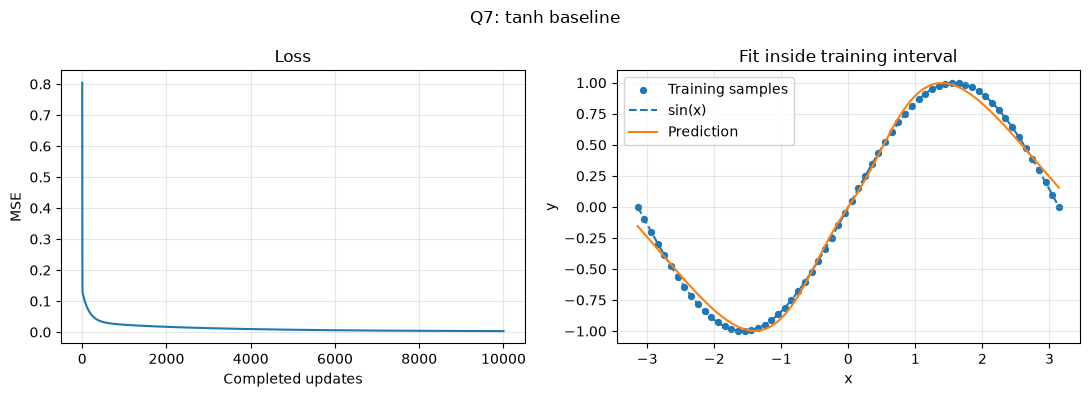

In [14]:
base_net = TwoLayerNet(hidden_dim=HIDDEN_DIM, seed=SEED, activation="tanh")
base_history, base_info = train(base_net, X, y, lr=LR, epochs=EPOCHS)
base_grid_pred, _ = base_net.forward(grid)
print(base_info)
print("final training MSE:", base_history[-1])
print("in-interval grid MSE:", mse_loss(base_grid_pred, np.sin(grid)))
assert len(base_history) == base_info["completed_updates"] + 1
assert np.isclose(base_history[-1], mse_loss(base_net.forward(X)[0], y))
plot_results(X, y, grid, base_grid_pred, base_history, title="Q7: tanh baseline")
plt.show()


**参考分析：** 默认设置训练 MSE 约 0.00328（具体值以上方运行结果为准）。检查预测曲线在端点等位置的残差，并同时看损失是否仍在缓慢下降。
损失变小表示训练样本整体误差减小，不保证所有位置精确相等。400 点网格仍在 [−π,π] 内，只检验区间内拟合；它既不是外推实验，也不能据此宣称真实测试泛化。


## Q8 · 去掉非线性激活的受控对照（必做）

**运行前先填写预测，再执行代码。** 保持数据、初始化参数、H、lr、训练次数完全相同，只将 activation 从 tanh 改成 linear。
不能用训练后的 tanh 参数作为 linear 的初始化。记录两组最终损失及曲线，推导 linear 网络等价于什么函数。

| 条件   | 事前预测         | 实际损失 / status      | 曲线证据                   | 解释                       |
| ------ | ---------------- | ---------------------- | -------------------------- | -------------------------- |
| tanh   | 能表达非线性弯曲 | 约 0.00328 / completed | 曲线贴近正弦，端点仍有残差 | 非线性激活改变表达能力     |
| linear | 只能拟合直线     | 约 0.20718 / completed | 预测为直线，无法匹配峰谷   | 两个仿射层复合仍为仿射函数 |


**参考事前预测：** linear 隐藏层与线性输出复合后仍为仿射函数，不能表达正弦弯曲；训练能下降，但最终会有明显表达能力误差。


tanh: 0.0032783013417772705 {'status': 'completed', 'completed_updates': 10000, 'attempted_update': 10000, 'lr': 0.02}
linear: 0.20718447504846849 {'status': 'completed', 'completed_updates': 10000, 'attempted_update': 10000, 'lr': 0.02}


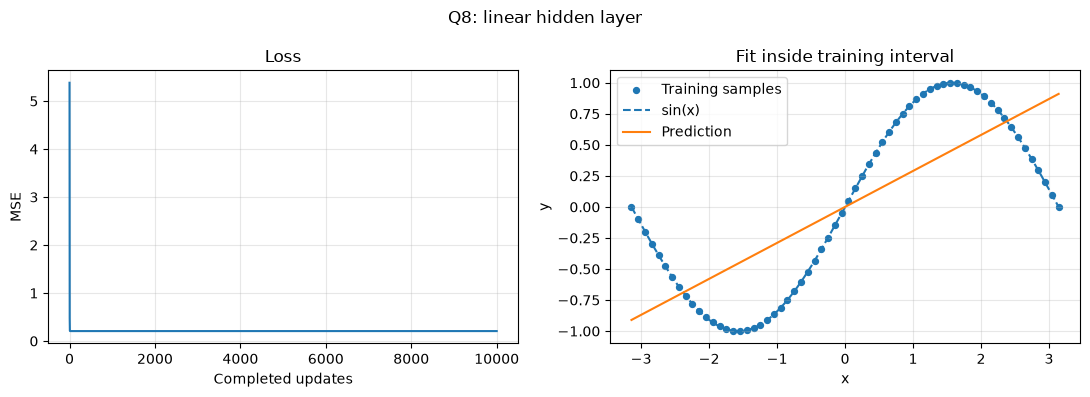

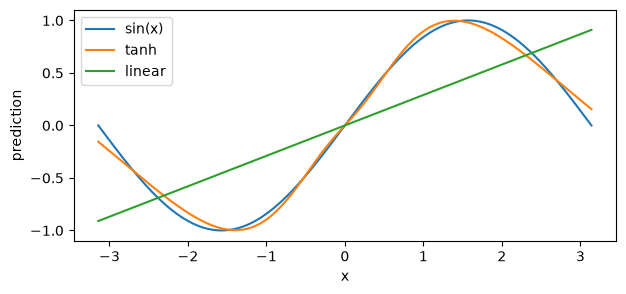

In [15]:
initial_tanh = TwoLayerNet(hidden_dim=HIDDEN_DIM, seed=SEED, activation="tanh")
linear_net = TwoLayerNet(hidden_dim=HIDDEN_DIM, seed=SEED, activation="linear")
for name in initial_tanh.params:
    np.testing.assert_array_equal(initial_tanh.params[name], linear_net.params[name])
linear_history, linear_info = train(linear_net, X, y, lr=LR, epochs=EPOCHS)
linear_grid_pred, _ = linear_net.forward(grid)
print("tanh:", base_history[-1], base_info)
print("linear:", linear_history[-1], linear_info)
plot_results(
    X, y, grid, linear_grid_pred, linear_history, title="Q8: linear hidden layer"
)
plt.show()
plt.figure(figsize=(7, 3))
plt.plot(grid[:, 0], np.sin(grid[:, 0]), label="sin(x)")
plt.plot(grid[:, 0], base_grid_pred[:, 0], label="tanh")
plt.plot(grid[:, 0], linear_grid_pred[:, 0], label="linear")
plt.xlabel("x")
plt.ylabel("prediction")
plt.legend()
plt.show()


**参考事后解释：** linear 的预测为 X(W1W2)+(b1W2+b2)，一维输入下就是 ax+b。默认损失约 0.20718，高于 tanh 的约 0.00328。
这不是单凭损失较高判断“代码错了”：其梯度检查通过，预测曲线又符合仿射表达式，说明主要限制来自函数族。增加线性隐藏宽度仍无法改变该表达式。


## Q9 · 学习率对照（进阶）

**先预测再运行。** 比较 lr=0.002、0.02、0.2，其余设置与 Q7 完全一致，每次重新创建同一 seed 的模型。
分别记录初始损失、最终有限损失、完成更新次数、status 和曲线。停止后的“最后有限损失”不得称为收敛损失。

| lr    | 事前预测           | 完成步数         | status                  | 最后有限 MSE | 事后解释                   |
| ----- | ------------------ | ---------------- | ----------------------- | ------------ | -------------------------- |
| 0.002 | 固定预算下改善较慢 | 10000            | completed               | 约 0.02364   | 尚高于基准误差             |
| 0.02  | 预计稳定下降       | 10000            | completed               | 约 0.00328   | 该设置下拟合较好           |
| 0.2   | 可能发散或溢出     | 本验证环境为 252 | 第 253 次尝试溢出后回滚 | 约 2.29e305  | 损失急剧增大，不能称为收敛 |

异常步数依赖浮点环境，以上是本次验证记录，评分应以实际输出和解释为准。


**参考事前预测：** 小学习率在固定更新次数下可能较慢；基准学习率预计稳定；大学习率可能振荡、发散或溢出。实际结论必须由本次运行支持，不能把“较大”直接等同于所有情形下必然发散。


{'lr': 0.002, 'initial_loss': np.float64(0.8042417068752801), 'last_finite_loss': np.float64(0.02364156602749766), 'status': 'completed', 'completed_updates': 10000, 'attempted_update': 10000}
{'lr': 0.02, 'initial_loss': np.float64(0.8042417068752801), 'last_finite_loss': np.float64(0.0032783013417772705), 'status': 'completed', 'completed_updates': 10000, 'attempted_update': 10000}
{'lr': 0.2, 'initial_loss': np.float64(0.8042417068752801), 'last_finite_loss': np.float64(2.6155750320200412e+306), 'status': 'stopped at attempted update 251: overflow encountered in reduce', 'completed_updates': 250, 'attempted_update': 251}


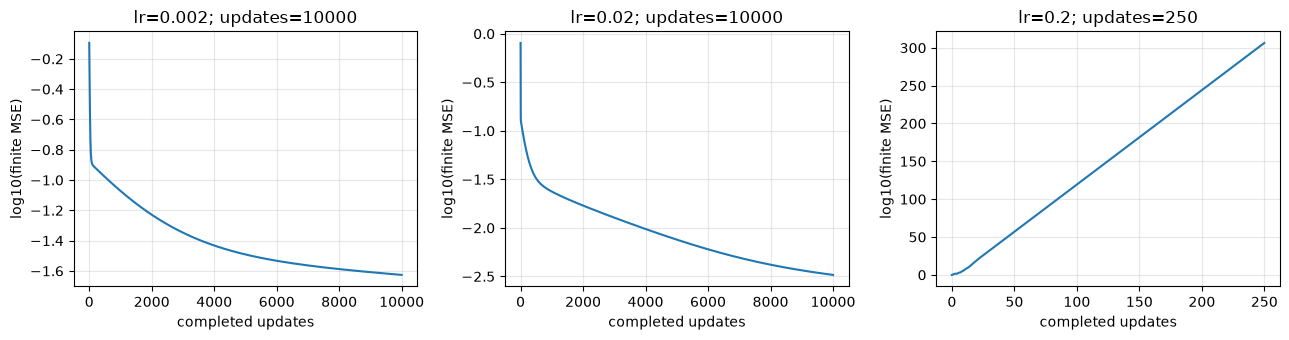

In [16]:
lr_runs = {}
for lr in (0.002, 0.02, 0.2):
    net = TwoLayerNet(hidden_dim=HIDDEN_DIM, seed=SEED, activation="tanh")
    for name in initial_tanh.params:
        np.testing.assert_array_equal(net.params[name], initial_tanh.params[name])
    history, info = train(net, X, y, lr=lr, epochs=EPOCHS)
    lr_runs[lr] = (net, history, info)
    print(
        {"lr": lr, "initial_loss": history[0], "last_finite_loss": history[-1], **info}
    )

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (lr, (_, history, info)) in zip(axes, lr_runs.items()):
    # 绘制 log10(MSE)，避免极大有限损失让对数刻度自动生成溢出的刻度。
    ax.plot(
        np.arange(len(history)), np.log10(np.maximum(history, np.finfo(float).tiny))
    )
    ax.set_title(f"lr={lr}; updates={info['completed_updates']}")
    ax.set_xlabel("completed updates")
    ax.set_ylabel("log10(finite MSE)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**参考事后解释：** 固定 10000 步下，lr=0.002 的训练 MSE 约 0.02364，比 lr=0.02 的约 0.00328 高，符合收敛速度较慢的预测。
lr=0.2 可能达到非有限值而提前停止，必须引用输出的 status 和实际步数。有限的巨大损失也表明不稳定，曲线因停止而截断不代表趋于平台。
各面板纵轴范围可能不同，比较时同时看刻度与打印数值。此对照只支持这些设置下的判断，不构成普遍最优学习率结论。


## Q10 · PyTorch 自动求导对照（可跳过的教师演示）

使用 Q5 的小网络、相同输入与参数、float64、相同均方误差，比较自动求导与 NumPy 手写梯度。
未安装 PyTorch 时直接跳过，不影响 Q1–Q8。这里不训练新模型，不引入优化器。

观察 `loss.backward()` 后参数是否改变，解释它替代了本实验哪一部分；参数更新仍由谁负责？


In [17]:
try:
    import torch
except ImportError:
    print("未安装 PyTorch，跳过 Q10；不影响必做任务。")
else:
    demo = TwoLayerNet(hidden_dim=3, seed=7, activation="tanh")
    np_pred, np_cache = demo.forward(X_small)
    np_grads = demo.backward(np_pred, y_small, np_cache)
    tx = torch.tensor(X_small, dtype=torch.float64)
    ty = torch.tensor(y_small, dtype=torch.float64)
    tp = {
        k: torch.tensor(v.copy(), dtype=torch.float64, requires_grad=True)
        for k, v in demo.params.items()
    }
    torch_pred = torch.tanh(tx @ tp["W1"] + tp["b1"]) @ tp["W2"] + tp["b2"]
    torch_loss = ((torch_pred - ty) ** 2).mean()
    np.testing.assert_allclose(torch_pred.detach().numpy(), np_pred)
    assert np.isclose(torch_loss.item(), mse_loss(np_pred, y_small))
    torch_loss.backward()
    for name in tp:
        auto_grad = tp[name].grad.detach().numpy()
        np.testing.assert_allclose(auto_grad, np_grads[name], rtol=1e-10, atol=1e-12)
        np.testing.assert_array_equal(tp[name].detach().numpy(), demo.params[name])
        print(name, "max abs difference:", np.max(np.abs(auto_grad - np_grads[name])))
    print("自动求导与手写 BP 对齐；backward 后参数保持不变。")


未安装 PyTorch，跳过 Q10；不影响必做任务。


**参考解释：** 自动求导根据计算图应用链式法则，替代 Q4 的手写反向计算；forward 与损失仍由程序定义。`backward()` 填充梯度，不执行梯度下降；参数更新仍需显式操作或优化器。重复 backward 还需注意梯度累加，本演示每次重新创建张量。


## 提交前：真实排错记录与可复现检查

记录一次你实际经历的排错，不能将下面的模板当作已经发生的经历。如果没有自然出现的问题，可主动注入一个错误（例如偏置对样本求平均或梯度重复除以 N），真实运行、观察失败并修复，明确标注“主动注入”。

| 项目                                | 你的记录 |
| ----------------------------------- | -------- |
| 现象与最小复现输入                  | 待填     |
| 初始猜测                            | 待填     |
| 定位依据（实际报错、形状或数值）    | 待填     |
| 根因与修改                          | 待填     |
| 修复后的独立验证结果                | 待填     |
| 若使用 AI，采用了哪些建议、如何核实 | 待填     |

提交学生 notebook、`nn_numpy.py` 和以上真实记录，保留 Q5 梯度检查、Q7 两张曲线、Q8 的预测/证据/解释。
运行过的 Q9、Q10 保留结果，未做标注跳过。提交前重启 kernel，按照单元顺序全量运行；不要依赖历史变量状态。
评分看数学解释、独立验证、对照控制、真实排错与可复现性，不以代码行数或单一最终损失评分。


**教师提示：** 参考答案不编造“学生真实排错经历”。可让学生在 Q4 将 db1 的 sum 改为 mean，再比较 Q5 中 b1 误差；修复并再次运行，将真实输出写入记录。其它候选错误包括 y 变为一维、漏写 tanh 导数、在 backward 中更新参数。
